In [12]:
# calculate the leakage of each csem and the entire station
import pandas as pd

C_LEAK = 2520.0

df = pd.read_csv("/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE2027July/fused data.csv", encoding="utf-8-sig")

cr_cols = [f"Nb CR {y}" for y in range(2010, 2025)]
cr_cols = [c for c in cr_cols if c in df.columns]

for c in cr_cols + ["Masse rejetée à chaque CR (kg)"]:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(",", ".", regex=False), errors="coerce")

df["annual leakage (kg)"] = df[cr_cols].sum(axis=1) * df["Masse rejetée à chaque CR (kg)"]
total_leakage = df["annual leakage (kg)"].sum()
df["annual leakage cost (€)"] = df["annual leakage (kg)"] * C_LEAK


print("Total leakage (kg):", total_leakage)
print("Total leakage cost (€):", df["annual leakage cost (€)"].sum())

result = df[["N Equipement", "annual leakage (kg)", "annual leakage cost (€)"]].copy()
result.to_csv("Result_reference/reference_results.csv", index=False, encoding="utf-8-sig")
print(result)

Total leakage (kg): 33279.25415
Total leakage cost (€): 83863720.458
      N Equipement  annual leakage (kg)  annual leakage cost (€)
0       5000002434              92.0160               231880.320
1       5000002436               5.3250                13419.000
2       5000002439              12.6380                31847.760
3       5000002490              39.7600               100195.200
4       5000002492              36.9200                93038.400
...            ...                  ...                      ...
2837    5002737625               0.4814                 1213.128
2838    5002739072               2.5752                 6489.504
2839    5002743369               0.0000                    0.000
2840    5002744302               0.4060                 1023.120
2841    5002895051               6.1200                15422.400

[2842 rows x 3 columns]


In [1]:
# calculate the leakage of each csem and the entire station
import pandas as pd


C_LEAK = 2520.0


df = pd.read_csv(
    "/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE2027July/fused data.csv",
    encoding="utf-8-sig"
)


cr_cols = [f"Nb CR {y}" for y in range(2010, 2025)]
cr_cols = [c for c in cr_cols if c in df.columns]


for c in cr_cols + ["Masse rejetée à chaque CR (kg)"]:
    df[c] = pd.to_numeric(
        df[c].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

# 将可能的 NaN 填为 0，避免后续求和出现问题
df[cr_cols + ["Masse rejetée à chaque CR (kg)"]] = df[
    cr_cols + ["Masse rejetée à chaque CR (kg)"]
].fillna(0.0)


# =========================
# 1. 计算每年所有 equipment 的泄漏总量（修正版）
# =========================
years = range(2010, 2025)
annual_leakage_by_year = {}

for y in years:
    col = f"Nb CR {y}"
    if col in df.columns:
        # 每个设备：该年 CR 次数 * 该设备每次 CR 泄漏质量
        # 然后对所有设备求和
        annual_leakage_by_year[y] = (df[col] * df["Masse rejetée à chaque CR (kg)"]).sum()
    else:
        annual_leakage_by_year[y] = 0.0


# 打印每年泄漏量
print("\n=== Annual leakage by year (kg) ===")
for y, leak in annual_leakage_by_year.items():
    print(f"{y}: {leak:.2f} kg")


# 保存为 CSV
annual_df = pd.DataFrame(
    list(annual_leakage_by_year.items()),
    columns=["Year", "Total leakage (kg)"]
)
annual_df.to_csv(
    "Result_reference/annual_leakage_by_year.csv",
    index=False,
    encoding="utf-8-sig"
)


# =========================
# 2. 原有逻辑：每个 equipment 的总泄漏（所有年份加总）
# =========================
df["annual leakage (kg)"] = df[cr_cols].sum(axis=1) * df["Masse rejetée à chaque CR (kg)"]
total_leakage = df["annual leakage (kg)"].sum()
df["annual leakage cost (€)"] = df["annual leakage (kg)"] * C_LEAK


print("\nTotal leakage (kg):", total_leakage)
print("Total leakage cost (€):", df["annual leakage cost (€)"].sum())


result = df[["N Equipement", "annual leakage (kg)", "annual leakage cost (€)"]].copy()
result.to_csv(
    "Result_reference/reference_results.csv",
    index=False,
    encoding="utf-8-sig"
)
print(result)


# =========================
# 3. 一致性检查（可选）
# =========================
sum_over_years = sum(annual_leakage_by_year.values())
print("\nConsistency check:")
print("Sum of annual leakage over years (kg):", sum_over_years)
print("Total leakage from df (kg):", total_leakage)
print("Difference (kg):", abs(sum_over_years - total_leakage))


=== Annual leakage by year (kg) ===
2010: 3332.86 kg
2011: 2568.47 kg
2012: 2358.51 kg
2013: 2447.24 kg
2014: 2167.99 kg
2015: 2435.28 kg
2016: 2591.25 kg
2017: 2375.81 kg
2018: 2909.43 kg
2019: 2403.78 kg
2020: 1977.81 kg
2021: 1916.69 kg
2022: 1434.73 kg
2023: 1121.44 kg
2024: 1237.96 kg

Total leakage (kg): 33279.25415
Total leakage cost (€): 83863720.458
      N Equipement  annual leakage (kg)  annual leakage cost (€)
0       5000002434              92.0160               231880.320
1       5000002436               5.3250                13419.000
2       5000002439              12.6380                31847.760
3       5000002490              39.7600               100195.200
4       5000002492              36.9200                93038.400
...            ...                  ...                      ...
2837    5002737625               0.4814                 1213.128
2838    5002739072               2.5752                 6489.504
2839    5002743369               0.0000              

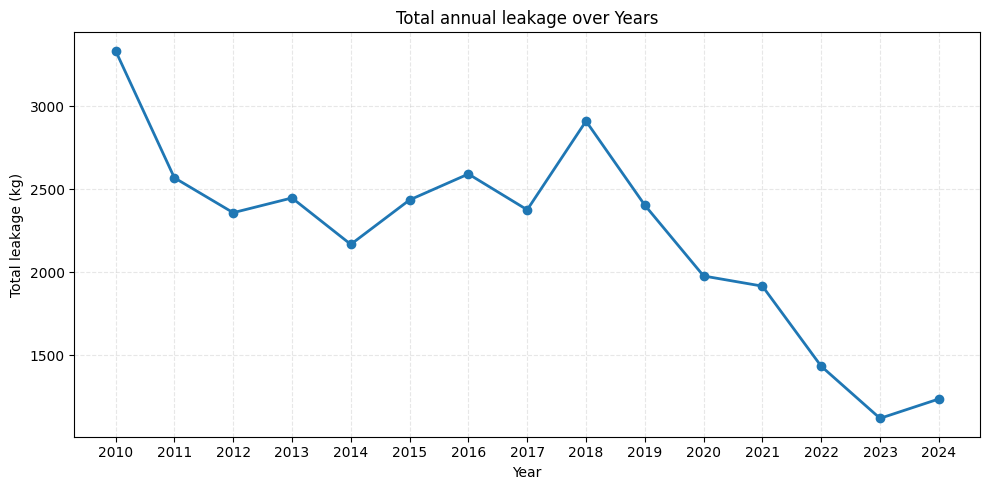

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# 读取 CSV（把 'your_data.csv' 换成你的文件名/路径）
df = pd.read_csv("/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE2027July/4Method/Result_reference/annual_leakage_by_year.csv")

# 确保按年份排序（可选，但推荐）
df = df.sort_values("Year")

# 绘图
plt.figure(figsize=(10, 5))
plt.plot(df["Year"], df["Total leakage (kg)"], marker="o", linewidth=2, markersize=6)

plt.xlabel("Year")
plt.ylabel("Total leakage (kg)")
plt.title("Total annual leakage over Years")

# 如果年份是整数且不多，可以显示每一年
if (df["Year"].max() - df["Year"].min()) <= 20:
    plt.xticks(df["Year"])

plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()